# 13 - First-order models

**MATH 331 - Differential Equations.** Lecture plan: Sessions 7 and 8 (Unit 4: cooling, mixing tanks, phase line; falling bodies with drag, RC and RL circuits, preview of Euler's method).

**References**
* J. Lebl, *Notes on Diffy Qs*: Example 1.3.3 and Exercise 1.3.12 (cooling); Example 1.4.2 and
  Exercises 1.4.6, 1.4.8, 1.4.9, 1.4.12 (mixing); Section 1.6 (phase line); Section 1.7 (Euler's
  method).
* Exercise numbers are those of the exercise lists at the end of each chapter of the
  LibreTexts edition, unless "in the text" is said.
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012): Section 1.4,
  Example 11 (mixing); Section 3.7 (resistor, capacitor, inductor).
* Falling bodies and first-order circuits are derived here from Newton's second law and
  Kirchhoff's voltage law.
* Related notebooks: 01 and 02 (growth and decay), 03 (logistic equation, phase line), 04
  (Euler's method in depth), 10 and 11 (the methods used here).

**What you will learn**
1. To **build** a model from a verbal description: a balance of rates.
2. That cooling, mixing, drag and two circuits are **one equation**, with one equilibrium and one
   time constant, which you can read without solving.
3. What changes when a model is not of this type: a tank that fills up, drag proportional to
   $v^2$.
4. A first comparison of Euler's method with an exact solution, and how it can fail.

## 1. Theory in brief

**A model is a balance.** For a quantity $x(t)$ in a container (heat in a cup, salt in a tank,
momentum of a body, charge on a capacitor):

$$ \frac{dx}{dt} = \text{rate in} - \text{rate out} . $$

**The equation of this notebook.** In many models the right-hand side is a constant minus a
multiple of $x$. Written with two numbers that have a meaning,

$$ \boxed{\;\frac{dx}{dt} = \frac{x_\infty - x}{\tau}\;} \qquad\Longrightarrow\qquad
x(t) = x_\infty + (x_0 - x_\infty)\,e^{-t/\tau} $$

(linear, and separable: notebooks 10 and 11).

* $x_\infty$ is the **equilibrium**: where $x' = 0$. It is **stable**: if $x < x_\infty$ then
  $x' > 0$ and $x$ rises towards it; if $x > x_\infty$ it falls towards it: this is how Lebl
  (Section 1.6) reads stability, from the sign of $f$ on each side. A quick test that says the
  same: for $x' = f(x)$, an equilibrium is stable when $f'(x_\infty) < 0$; here
  $f' = -1/\tau < 0$.
* $\tau$ is the **time constant**: after a time $\tau$ the gap $x_\infty - x$ is multiplied by
  $e^{-1} \approx 0.37$. So $63\,\%$ of the gap is closed after $\tau$, $95\,\%$ after $3\tau$,
  $99\,\%$ after $5\tau$.

To use this, write your equation as $x' = a - b\,x$: then $\tau = 1/b$ and $x_\infty = a/b$.
**No solving is needed.**

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: relaxation, quadratic_drag_velocity, linear_first_order, euler, phase_line, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. One equation, five stories

| Story | Law | Equation | $x_\infty$ | $\tau$ |
|---|---|---|---|---|
| Cooling (coffee) | Newton's law of cooling | $T' = -k\,(T - T_{room})$ | $T_{room}$ | $1/k$ |
| Mixing, constant volume $V$, flow $r$, incoming concentration $c_{in}$ | balance of salt | $x' = r\,c_{in} - \dfrac{r}{V}\,x$ | $V c_{in}$ | $V/r$ |
| Falling body, drag $k v$ | Newton's second law | $m v' = mg - k v$ | $mg/k$ | $m/k$ |
| RC circuit, battery $E$ | Kirchhoff's voltage law | $R\,q' + \dfrac{q}{C} = E$ | $CE$ | $RC$ |
| RL circuit, battery $E$ | Kirchhoff's voltage law | $L\,i' + R\,i = E$ | $E/R$ | $L/R$ |

Five different laws of physics, the same mathematics. The data below are those used in the rest
of the notebook. To compare them we plot, for each story, the **fraction of the gap closed**,
$\dfrac{x - x_0}{x_\infty - x_0}$, against the time measured in time constants, $t/\tau$.

coffee          x0 =       90   x_inf =       20   tau =    32.44
salt in a tank  x0 =     1000   x_inf =     4000   tau =    3.333
falling body    x0 =        0   x_inf =    56.03   tau =    5.711
RC circuit      x0 =        0   x_inf =    0.005   tau =        1
RL circuit      x0 =        0   x_inf =    0.005   tau =   0.0005


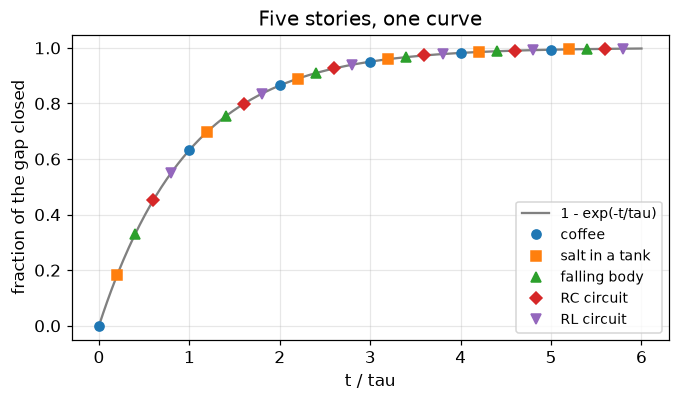

In [2]:
G = ol.GRAVITY                              # 9.81 m/s^2

# the coffee of Lecture 1: 90 degrees, 80 after 5 minutes, room at 20
T_START, T_LATER, T_ROOM, MINUTES_LATER = 90.0, 80.0, 20.0, 5.0
k_cooling = np.log((T_START - T_ROOM) / (T_LATER - T_ROOM)) / MINUTES_LATER

# the tank of Adkins and Davidson, Example 11
VOLUME, FLOW, C_START, C_IN = 10.0, 3.0, 100.0, 400.0      # L, L/min, g/L, g/L

# a skydiver; the linear drag constant is chosen in Section 5
MASS = 80.0                                 # kg
DRAG_QUADRATIC = 0.25                       # kg/m
v_terminal = np.sqrt(MASS * G / DRAG_QUADRATIC)
drag_linear = MASS * G / v_terminal         # kg/s: the same terminal velocity with linear drag

# two circuits
RESISTANCE, CAPACITANCE, INDUCTANCE, VOLTAGE = 1000.0, 1e-3, 0.5, 5.0   # ohm, farad, henry, volt

#          name                 x0                 x_inf                      tau
STORIES = (("coffee",           T_START,           T_ROOM,                    1 / k_cooling),
           ("salt in a tank",   VOLUME * C_START,  VOLUME * C_IN,             VOLUME / FLOW),
           ("falling body",     0.0,               MASS * G / drag_linear,    MASS / drag_linear),
           ("RC circuit",       0.0,               CAPACITANCE * VOLTAGE,     RESISTANCE * CAPACITANCE),
           ("RL circuit",       0.0,               VOLTAGE / RESISTANCE,      INDUCTANCE / RESISTANCE))
MARKERS = ("o", "s", "^", "D", "v")
WIDE_FIGURE = (7.0, 3.6)
N_POINTS = 400
TAUS_SHOWN = 6.0

for name, x0, x_inf, tau in STORIES:
    print(f"{name:15s} x0 = {x0:8.4g}   x_inf = {x_inf:8.4g}   tau = {tau:8.4g}")

s_fine = np.linspace(0.0, TAUS_SHOWN, N_POINTS)
fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.plot(s_fine, 1 - np.exp(-s_fine), "-", color="gray", label="1 - exp(-t/tau)")
for index, ((name, x0, x_inf, tau), marker) in enumerate(zip(STORIES, MARKERS)):
    s_marks = np.arange(index / len(STORIES), TAUS_SHOWN, 1.0)        # staggered, to see every marker
    fraction = (ol.relaxation(s_marks * tau, x0, x_inf, tau) - x0) / (x_inf - x0)
    ax.plot(s_marks, fraction, marker, label=name)
    assert np.allclose(fraction, 1 - np.exp(-s_marks))                # the same curve for all
ax.set_xlabel("t / tau")
ax.set_ylabel("fraction of the gap closed")
ax.set_title("Five stories, one curve")
ax.legend(loc="lower right")
plt.show()

*The plot shows* one grey curve rising from 0 towards 1, steeply at first and then more and more
slowly. The markers of the five stories (circles, squares, triangles, diamonds, inverted
triangles) all lie on it: at $t = \tau$ the fraction is 0.63, at $t = 3\tau$ it is 0.95.

The time constants are very different: half an hour for the coffee, three minutes for the tank,
six seconds for the falling body, one second for the RC circuit, half a millisecond for the RL
circuit. Measured in its own time constant, each story is the same.

## 3. Equilibrium and stability

The **phase line** (Lebl, Section 1.6; notebook 03) shows an autonomous equation $x' = f(x)$
without solving it: a line of values of $x$, a dot at each equilibrium, an arrow upwards where
$f > 0$ and downwards where $f < 0$.

For $x' = (x_\infty - x)/\tau$ there is one equilibrium, and both arrows point towards it:
stable. Compare with the logistic equation of notebook 03, which has two equilibria, one stable
and one unstable.

**Before running the cell:** in the picture, where is the solution after one time constant?
After five?

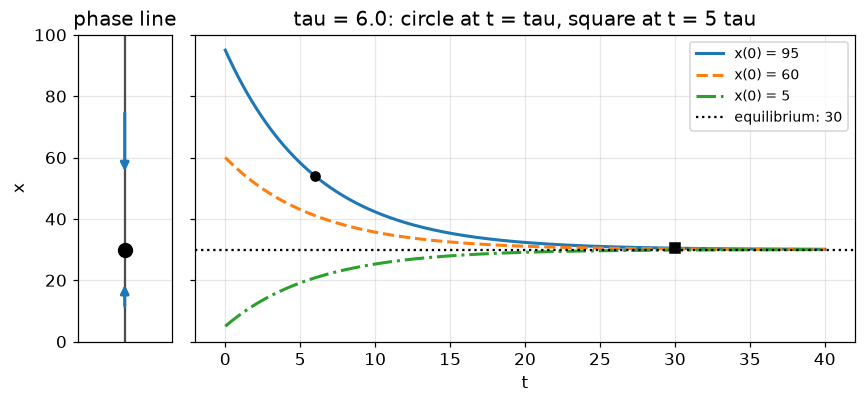

f'(x_inf) = -1/tau < 0: stable


In [3]:
X_AXIS = (0.0, 100.0)
PLOT_TIME = 40.0
START_VALUES = (95.0, 60.0, 5.0)
START_STYLES = ("-", "--", "-.")
PANEL_WIDTHS = (1, 7)
TWO_PANELS = (8.0, 3.8)


def plot_relaxation(x0=START_VALUES[0], x_inf=30.0, tau=6.0):
    times = np.linspace(0.0, PLOT_TIME, N_POINTS)
    fig, (line_ax, ax) = plt.subplots(1, 2, figsize=TWO_PANELS, sharey=True,
                                      gridspec_kw={"width_ratios": PANEL_WIDTHS})
    ol.phase_line(line_ax, lambda value: (x_inf - value) / tau, [x_inf], X_AXIS)
    line_ax.set_ylabel("x")
    line_ax.set_title("phase line")
    for start, style in zip((x0,) + START_VALUES[1:], START_STYLES):
        ax.plot(times, ol.relaxation(times, start, x_inf, tau), linestyle=style, linewidth=2,
                label=f"x(0) = {start:.0f}")
    ax.axhline(x_inf, linestyle=":", color="black", label=f"equilibrium: {x_inf:.0f}")
    for multiple, marker in ((1, "o"), (5, "s")):
        if multiple * tau <= PLOT_TIME:
            ax.plot(multiple * tau, ol.relaxation(multiple * tau, x0, x_inf, tau), marker, color="black")
    ax.set_xlabel("t")
    ax.set_title(f"tau = {tau:.1f}: circle at t = tau, square at t = 5 tau")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


plot_relaxation()
print("f'(x_inf) = -1/tau < 0:", ol.classify_equilibrium(-1.0))
assert ol.classify_equilibrium(-1.0) == "stable"

*The plot shows*, on the left, the phase line: a vertical line with a filled dot at the
equilibrium $x = 30$ and two arrows pointing towards it. On the right, three solutions starting
from 95, 60 and 5 all approach the dotted line $x = 30$. On the first one, the circle marks
$t = \tau$ (63 % of the way) and the square $t = 5\tau$ (practically arrived).

**Sliders.** Before moving them: if $\tau$ is doubled, where does the circle go? Does the
equilibrium move?

In [4]:
VALUE_STEP = 5.0
TAU_RANGE = (1.0, 20.0, 0.5)            # minimum, maximum, step

interact(plot_relaxation,
         x0=FloatSlider(value=START_VALUES[0], min=X_AXIS[0], max=X_AXIS[1], step=VALUE_STEP,
                        description="x(0)", continuous_update=False),
         x_inf=FloatSlider(value=30.0, min=X_AXIS[0] + VALUE_STEP, max=X_AXIS[1] - VALUE_STEP, step=VALUE_STEP,
                           description="x_inf", continuous_update=False),
         tau=FloatSlider(value=6.0, min=TAU_RANGE[0], max=TAU_RANGE[1], step=TAU_RANGE[2],
                         description="tau", continuous_update=False));

interactive(children=(FloatSlider(value=95.0, continuous_update=False, description='x(0)', step=5.0), FloatSli...

## 4. Building a mixing model from words

**The recipe.** Let $x(t)$ be the **amount** of salt (not the concentration). Then

$$ x' = (\text{flow in}) \times (\text{concentration in}) \;-\; (\text{flow out}) \times \frac{x}{\text{volume}} , $$

because a well-stirred tank sends out its own concentration, $x/V$.

*Adkins and Davidson, Section 1.4, Example 11.* A tank contains 10 L of brine with 100 g/L of
salt. Brine with 400 g/L flows in at 3 L/min; the mixture flows out at 3 L/min. Find the amount
of salt $y(t)$.

* Start: $y(0) = 10 \times 100 = 1000$ g. The volume stays 10 L (3 in, 3 out).
* Balance: $y' = 3 \times 400 - 3 \times \dfrac{y}{10} = 1200 - \dfrac{3}{10}\,y$.
* Read: $\tau = \dfrac{10}{3}$ min, $y_\infty = \dfrac{1200}{3/10} = 4000$ g (that is 400 g/L, the
  incoming concentration: of course).
* So $y = 4000 - 3000\,e^{-3t/10}$, without any integration.

tau = 3.333 min   y_inf = 4000 g   y(0) = 1000 g


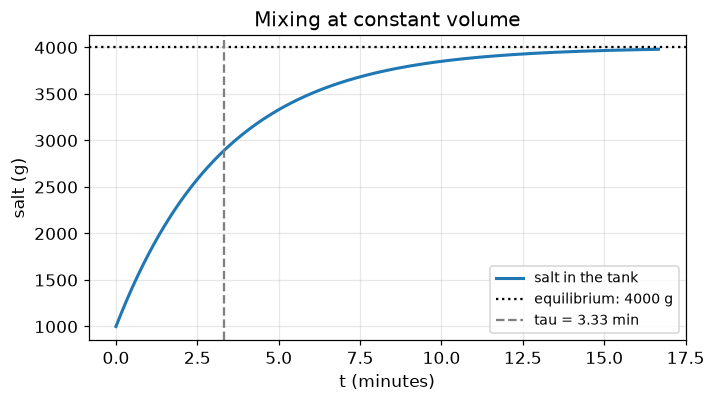

In [5]:
tau_tank = VOLUME / FLOW
y_inf_tank = VOLUME * C_IN
y_start_tank = VOLUME * C_START
print(f"tau = {tau_tank:.3f} min   y_inf = {y_inf_tank:.0f} g   y(0) = {y_start_tank:.0f} g")

minutes = np.linspace(0.0, 5 * tau_tank, N_POINTS)
salt = ol.relaxation(minutes, y_start_tank, y_inf_tank, tau_tank)
assert np.allclose(salt, 4000 - 3000 * np.exp(-3 * minutes / 10))        # the formula of the book

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.plot(minutes, salt, "-", linewidth=2, label="salt in the tank")
ax.axhline(y_inf_tank, linestyle=":", color="black", label=f"equilibrium: {y_inf_tank:.0f} g")
ax.axvline(tau_tank, linestyle="--", color="gray", label=f"tau = {tau_tank:.2f} min")
ax.set_xlabel("t (minutes)")
ax.set_ylabel("salt (g)")
ax.set_title("Mixing at constant volume")
ax.legend(loc="lower right")
plt.show()

*The plot shows* the salt rising from 1000 g towards the dotted line at 4000 g; at the dashed
vertical line, $t = \tau = 3.33$ min, it has covered 63 % of the way.

**When the volume changes.** *Lebl, Example 1.4.2.* A 100 L tank contains 10 kg of salt in 60 L
of water. Brine with 0.1 kg/L flows in at 5 L/min; the mixture flows out at 3 L/min. How much
salt is in the tank when it is full?

* Volume: $60 + (5 - 3)\,t$ litres. Full when $60 + 2t = 100$: $t = 20$ min.
* Balance: $x' = 5 \times 0.1 - 3 \times \dfrac{x}{60 + 2t}$, that is
  $\;x' + \dfrac{3}{60 + 2t}\,x = 0.5$, $\;x(0) = 10$.

Still linear, but the coefficient of $x$ now depends on $t$: there is **no** single time
constant and no equilibrium to read. The integrating factor (notebook 11) gives Lebl's formula
$x = \dfrac{60 + 2t}{10} + C\,(60 + 2t)^{-3/2}$ with $C = 4\cdot 60^{3/2}$; `ol.linear_first_order`
computes the same thing numerically.

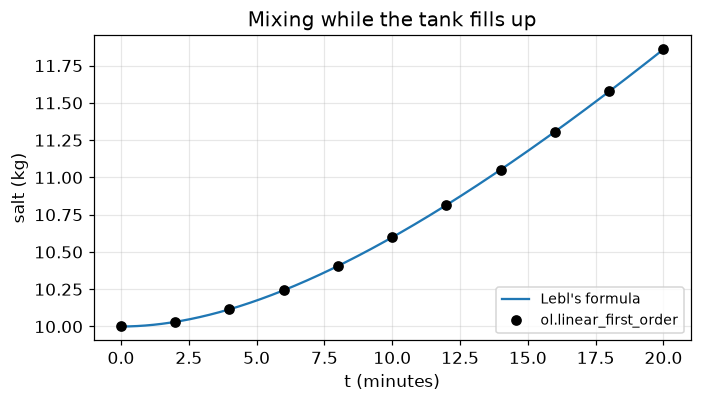

the tank is full at t = 20 min, with 11.86 kg of salt


In [6]:
V_START, V_FULL = 60.0, 100.0               # litres
RATE_IN, RATE_OUT, BRINE = 5.0, 3.0, 0.1    # L/min, L/min, kg/L
SALT_START = 10.0                           # kg
N_DOTS = 11

t_full = (V_FULL - V_START) / (RATE_IN - RATE_OUT)


def volume(t):
    return V_START + (RATE_IN - RATE_OUT) * t


def lebl_formula(t):
    constant = (SALT_START - V_START * BRINE) * V_START ** 1.5          # 4 (60^(3/2))
    return volume(t) * BRINE + constant * volume(t) ** -1.5


t_dots = np.linspace(0.0, t_full, N_DOTS)
salt_numerical = ol.linear_first_order(lambda s: RATE_OUT / volume(s), lambda s: RATE_IN * BRINE,
                                       0.0, SALT_START, t_dots)
t_fine = np.linspace(0.0, t_full, N_POINTS)

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.plot(t_fine, lebl_formula(t_fine), "-", label="Lebl's formula")
ax.plot(t_dots, salt_numerical, "o", color="black", label="ol.linear_first_order")
ax.set_xlabel("t (minutes)")
ax.set_ylabel("salt (kg)")
ax.set_title("Mixing while the tank fills up")
ax.legend(loc="lower right")
plt.show()

print(f"the tank is full at t = {t_full:.0f} min, with {salt_numerical[-1]:.2f} kg of salt")
assert np.allclose(salt_numerical, lebl_formula(t_dots))
assert np.isclose(salt_numerical[-1], 11.86, atol=0.005)                 # Lebl's answer

*The plot shows* the salt in the tank, starting at 10 kg with a horizontal tangent (at the first
instant the tank loses exactly as much salt as it receives: $0.5 - 3 \times 10/60 = 0$) and then
rising faster and faster to 11.86 kg at $t = 20$ minutes, when the tank is full. Dots
(numerical) and line (formula) agree.

## 5. Falling with drag

A body of mass $m$ falls; $v$ is its velocity, positive downwards. Newton's second law:

$$ m\,v' = mg - \text{drag} . $$

**Terminal velocity, without solving.** The velocity stops changing when $v' = 0$, that is when
the drag equals the weight.

* *Linear drag* $k\,v$ (small, slow bodies): $v_T = \dfrac{mg}{k}$ (the $x_\infty$ of this model), and the equation is our
  $x' = (x_\infty - x)/\tau$ with $\tau = m/k$.
* *Quadratic drag* $c\,v^2$ (a skydiver, a ball): $mg = c\,v_T^2$, so
  $\;v_T = \sqrt{\dfrac{mg}{c}}$.

The quadratic model is **not** linear, but it is separable. With $v(0) = 0$ (partial fractions,
video R04):

$$ \frac{dv}{1 - v^2/v_T^2} = g\,dt \quad\Longrightarrow\quad v(t) = v_T\,\tanh\!\Big(\frac{g\,t}{v_T}\Big) . $$

**Data.** A skydiver of 80 kg with $c = 0.25$ kg/m. For comparison, a linear drag with the same
terminal velocity.

terminal velocity: 56.0 m/s = 202 km/h
quadratic drag: 95% of it after 10.5 s;   linear drag: tau = 5.71 s, 95% after 17.1 s


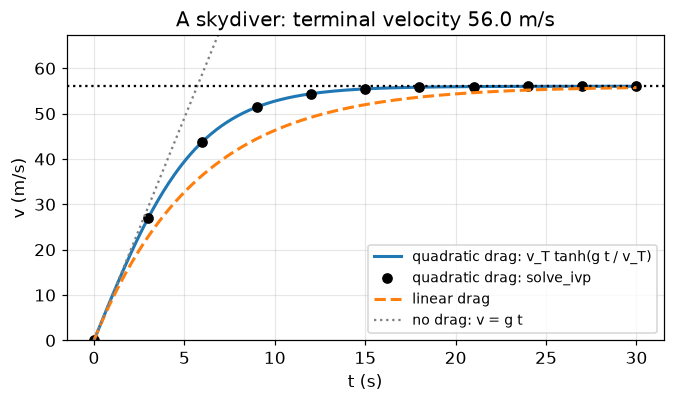

In [7]:
t_sym = sp.symbols("t")
v_T, g_sym = sp.symbols("v_T g", positive=True)
formula = v_T * sp.tanh(g_sym * t_sym / v_T)
assert sp.simplify(sp.diff(formula, t_sym) - g_sym * (1 - formula ** 2 / v_T ** 2)) == 0   # it solves the equation

KMH_PER_MS = 3.6
FALL_TIME = 30.0                            # seconds
NEARLY = 0.95
TOLERANCE = 1e-9

tau_fall = MASS / drag_linear
t_nearly = np.arctanh(NEARLY) * v_terminal / G
print(f"terminal velocity: {v_terminal:.1f} m/s = {v_terminal * KMH_PER_MS:.0f} km/h")
print(f"quadratic drag: {NEARLY:.0%} of it after {t_nearly:.1f} s;   "
      f"linear drag: tau = {tau_fall:.2f} s, {NEARLY:.0%} after {-np.log(1 - NEARLY) * tau_fall:.1f} s")

seconds = np.linspace(0.0, FALL_TIME, N_POINTS)
second_dots = np.linspace(0.0, FALL_TIME, N_DOTS)
numerical = solve_ivp(lambda s, v: G - DRAG_QUADRATIC / MASS * v ** 2, (0.0, FALL_TIME), [0.0],
                      dense_output=True, rtol=TOLERANCE, atol=TOLERANCE)

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.plot(seconds, ol.quadratic_drag_velocity(seconds, v_terminal, G), "-", linewidth=2, label="quadratic drag: v_T tanh(g t / v_T)")
ax.plot(second_dots, numerical.sol(second_dots)[0], "o", color="black", label="quadratic drag: solve_ivp")
ax.plot(seconds, ol.relaxation(seconds, 0.0, v_terminal, tau_fall), "--", linewidth=2, label="linear drag")
ax.plot(seconds, G * seconds, ":", color="gray", label="no drag: v = g t")
ax.axhline(v_terminal, linestyle=":", color="black")
ax.set_ylim(0.0, 1.2 * v_terminal)
ax.set_xlabel("t (s)")
ax.set_ylabel("v (m/s)")
ax.set_title(f"A skydiver: terminal velocity {v_terminal:.1f} m/s")
ax.legend(loc="lower right")
plt.show()

assert np.isclose(v_terminal, 56.0, atol=0.05) and np.isclose(t_nearly, 10.5, atol=0.05)
assert np.allclose(numerical.sol(second_dots)[0], ol.quadratic_drag_velocity(second_dots, v_terminal, G), atol=1e-6)

*The plot shows* the velocity against time. Without drag (dotted grey line) it would grow
without bound. With drag, both models start along that line and then bend towards the same
terminal velocity, 56 m/s (dotted black line); the quadratic one (solid) gets there sooner than
the linear one (dashed). The dots (numerical solution) lie on the solid curve (formula).

The terminal velocity was found **before** solving anything: it is the equilibrium of the
equation.

## 6. RC and RL circuits

Three components, three laws for the voltage across them (Adkins and Davidson, Section 3.7),
with $q$ the charge and $i = q'$ the current:

| Component | Voltage |
|---|---|
| resistor, resistance $R$ | $R\,i$ |
| capacitor, capacitance $C$ | $q / C$ |
| inductor (coil), inductance $L$ | $L\,i'$ |

**Kirchhoff's voltage law:** around a loop, the voltages of the components add up to the voltage
of the battery, $E$.

* **RC circuit** (battery, resistor, capacitor): $\;R\,q' + \dfrac{q}{C} = E$, so
  $\tau = RC$ and $q_\infty = CE$. Charging a capacitor.
* **RL circuit** (battery, resistor, coil): $\;L\,i' + R\,i = E$, so $\tau = \dfrac{L}{R}$ and
  $i_\infty = \dfrac{E}{R}$. Switching on a coil.

**Before running the cell:** the resistance is doubled. Does the RC circuit become slower or
faster? And the RL circuit? What happens to the final charge, and to the final current?

R = 1000 ohm:  RC: tau = 1.0 s, q_inf = 5.0 mC;   RL: tau = 0.50 ms, i_inf = 5.0 mA
R = 2000 ohm:  RC: tau = 2.0 s, q_inf = 5.0 mC;   RL: tau = 0.25 ms, i_inf = 2.5 mA


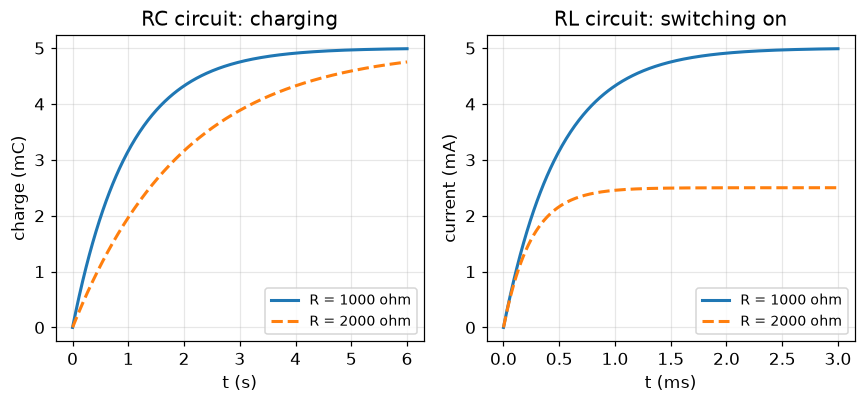

In [8]:
MILLI = 1e-3
DOUBLE = 2.0
CIRCUIT_STYLES = ("-", "--")

fig, (ax_rc, ax_rl) = plt.subplots(1, 2, figsize=TWO_PANELS)
for factor, style in zip((1.0, DOUBLE), CIRCUIT_STYLES):
    resistance = factor * RESISTANCE
    tau_rc, q_inf = resistance * CAPACITANCE, CAPACITANCE * VOLTAGE
    tau_rl, i_inf = INDUCTANCE / resistance, VOLTAGE / resistance
    print(f"R = {resistance:.0f} ohm:  RC: tau = {tau_rc:.1f} s, q_inf = {q_inf / MILLI:.1f} mC;   "
          f"RL: tau = {tau_rl / MILLI:.2f} ms, i_inf = {i_inf / MILLI:.1f} mA")
    t_rc = np.linspace(0.0, TAUS_SHOWN * RESISTANCE * CAPACITANCE, N_POINTS)
    t_rl = np.linspace(0.0, TAUS_SHOWN * INDUCTANCE / RESISTANCE, N_POINTS)
    ax_rc.plot(t_rc, ol.relaxation(t_rc, 0.0, q_inf, tau_rc) / MILLI, linestyle=style, linewidth=2,
               label=f"R = {resistance:.0f} ohm")
    ax_rl.plot(t_rl / MILLI, ol.relaxation(t_rl, 0.0, i_inf, tau_rl) / MILLI, linestyle=style, linewidth=2,
               label=f"R = {resistance:.0f} ohm")
ax_rc.set_xlabel("t (s)")
ax_rc.set_ylabel("charge (mC)")
ax_rc.set_title("RC circuit: charging")
ax_rc.legend(loc="lower right")
ax_rl.set_xlabel("t (ms)")
ax_rl.set_ylabel("current (mA)")
ax_rl.set_title("RL circuit: switching on")
ax_rl.legend(loc="lower right")
plt.tight_layout()
plt.show()

assert np.isclose(RESISTANCE * CAPACITANCE, 1.0) and np.isclose(INDUCTANCE / RESISTANCE, 0.5 * MILLI)

*The plot shows* two panels. Left, the charge of the capacitor against time in seconds: with
1000 ohm (solid) it rises to 5 mC with $\tau = 1$ s; with 2000 ohm (dashed) it reaches the
**same** 5 mC, more slowly ($\tau = 2$ s). Right, the current in the coil against time in
milliseconds: with 2000 ohm (dashed) it settles **faster** ($\tau = 0.25$ ms instead of 0.5 ms)
and at **half** the value (2.5 mA instead of 5 mA).

A larger resistance slows the RC circuit and speeds up the RL circuit: $\tau = RC$ against
$\tau = L/R$. You could say it from the table of Section 2, without any computation.

## 7. Euler's method against the exact solution

Most equations cannot be solved by a formula. **Euler's method** (Lebl, Section 1.7) is the
simplest way to compute a solution: from the point $(t_n, x_n)$, follow the slope for a step $h$,

$$ x_{n+1} = x_n + h\,f(t_n, x_n), \qquad t_{n+1} = t_n + h . $$

It is the slope field of notebook 09, followed one segment at a time. We try it where we know
the exact answer: the falling body with linear drag, $v' = (v_T - v)/\tau$.

**How good is it?** The error at a fixed time, for smaller and smaller steps:

In [9]:
def falling(t, v):
    return (v_terminal - v) / tau_fall


CHECK_TIME = 20.0                           # seconds
STEPS = (2.0, 1.0, 0.5, 0.25)               # each one half of the one before

exact_value = ol.relaxation(CHECK_TIME, 0.0, v_terminal, tau_fall)
errors = []
for h in STEPS:
    t_euler, v_euler = ol.euler(falling, (0.0, CHECK_TIME), [0.0], h)
    errors.append(abs(v_euler[-1] - exact_value))
    print(f"h = {h:5.2f} s   v({CHECK_TIME:.0f}) = {v_euler[-1]:.4f}   error = {errors[-1]:.4f}")
print(f"exact         v({CHECK_TIME:.0f}) = {exact_value:.4f}")
print("observed order:", np.round(ol.observed_order(errors), 2))

assert np.allclose(ol.observed_order(errors), 1.0, atol=0.1)             # first order

h =  2.00 s   v(20) = 55.2763   error = 0.9367
h =  1.00 s   v(20) = 54.8358   error = 0.4962
h =  0.50 s   v(20) = 54.5935   error = 0.2538
h =  0.25 s   v(20) = 54.4679   error = 0.1282
exact         v(20) = 54.3397
observed order: [0.92 0.97 0.99]


Each time the step is halved, the error is (about) halved: Euler's method is of **first order**.
Ten times more work, ten times less error. Notebook 04 explains why and shows better methods.

**How bad can it be?** Take a step larger than twice the time constant:

In [10]:
LONG_TIME = 50.0                            # seconds
BIG_STEP = 12.5                             # seconds: more than 2 tau

t_bad, v_bad = ol.euler(falling, (0.0, LONG_TIME), [0.0], BIG_STEP)
print(f"h = {BIG_STEP} s = {BIG_STEP / tau_fall:.2f} tau")
print("Euler:", np.round(v_bad, 0))
print("exact:", np.round(ol.relaxation(t_bad, 0.0, v_terminal, tau_fall), 0))
assert abs(v_bad[-1] - v_terminal) > abs(v_bad[1] - v_terminal)          # further away at every step

h = 12.5 s = 2.19 tau
Euler: [  0. 123. -23. 150. -56.]
exact: [ 0. 50. 55. 56. 56.]


The exact velocity rises quietly to 56 m/s. Euler's values jump above it, then below zero (the
skydiver going **up**), further away at each step: the numerical solution **explodes**, while
the true one is as tame as possible. Each Euler step multiplies the gap $v - v_T$ by
$(1 - h/\tau)$: for $h > 2\tau$ this number is smaller than $-1$.

**Slider.** The number of steps used to cover 40 seconds ($h = 40/N$). Before moving it: with
which $N$ does the computed velocity oscillate around the true one? With which $N$ does it
explode?

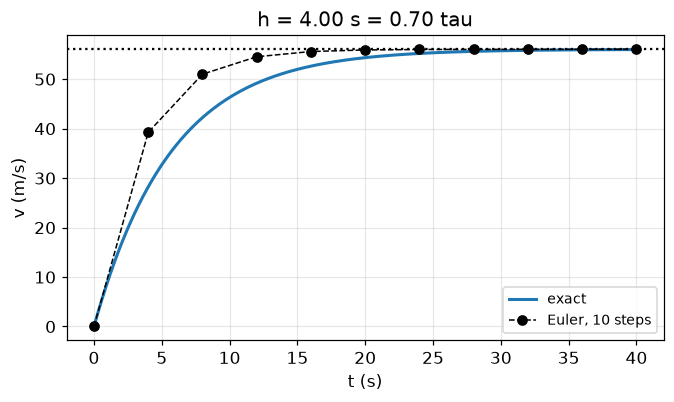

In [11]:
EULER_TIME = 40.0                           # seconds
DEFAULT_STEPS = 10


def plot_euler(n_steps=DEFAULT_STEPS):
    h = EULER_TIME / n_steps
    t_euler, v_euler = ol.euler(falling, (0.0, EULER_TIME), [0.0], h)
    times = np.linspace(0.0, EULER_TIME, N_POINTS)
    fig, ax = plt.subplots(figsize=WIDE_FIGURE)
    ax.plot(times, ol.relaxation(times, 0.0, v_terminal, tau_fall), "-", linewidth=2, label="exact")
    ax.plot(t_euler, v_euler, "o--", color="black", linewidth=1, label=f"Euler, {n_steps} steps")
    ax.axhline(v_terminal, linestyle=":", color="black")
    ax.set_xlabel("t (s)")
    ax.set_ylabel("v (m/s)")
    ax.set_title(f"h = {h:.2f} s = {h / tau_fall:.2f} tau")
    ax.legend(loc="lower right")
    plt.show()


plot_euler()

In [12]:
STEP_COUNTS = (3, 60)                       # fewest and most steps

interact(plot_euler,
         n_steps=IntSlider(value=DEFAULT_STEPS, min=STEP_COUNTS[0], max=STEP_COUNTS[1],
                           description="steps N", continuous_update=False));

interactive(children=(IntSlider(value=10, continuous_update=False, description='steps N', max=60, min=3), Outp...

(With $N = 4$ to $6$ the step is between $\tau$ and $2\tau$: the values jump across the true
curve and settle. With $N = 3$ the step is $2.3\,\tau$: they explode. With $N = 7$ the step is
almost exactly $\tau$, and the first step lands on the terminal velocity.)

> A numerical solution can be wrong in a way the exact solution never is. Always compare with
> something you know: an equilibrium, a time constant, a smaller step.

## 8. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

A quantity relaxes towards its equilibrium with time constant $\tau$.

* What fraction of the initial gap **is left** after $\tau$? After $3\tau$? (Two decimals.)
* In an RC circuit the resistance is doubled. By which factors are $\tau$ and the final charge
  multiplied?
* The same question for an RL circuit: $\tau$ and the final current.

Type three lists of two numbers.

In [13]:
my_fractions = None             # [left after tau, left after 3 tau], for example [0.5, 0.25]
my_rc_factors = None            # [factor of tau, factor of the final charge]
my_rl_factors = None            # [factor of tau, factor of the final current]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ROUNDING = 1e-2                 # two decimals are enough
ol.check("Exercise 1, fractions", my_fractions, np.exp([-1.0, -3.0]), tol=ROUNDING)
ol.check("Exercise 1, RC", my_rc_factors, [DOUBLE, 1.0])
ol.check("Exercise 1, RL", my_rl_factors, [1 / DOUBLE, 1 / DOUBLE]);

Exercise 1, fractions: no answer yet (replace None with your value)
Exercise 1, RC: no answer yet (replace None with your value)
Exercise 1, RL: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

Build each model, read $\tau$ and $x_\infty$ where you can, and type the number asked.

**(a)** *Lebl, Exercise 1.4.8.* 5 grams of salt are dissolved in 20 litres of water. Brine with
2 grams of salt per litre is added at 3 litres a minute; the tank is well mixed and is drained
at 3 litres a minute. After how many minutes are there 20 grams of salt in the tank?

**(b)** *Lebl, Exercise 1.4.9.* A tank contains 10 litres of pure water. Brine of unknown
concentration flows in at 1 litre per minute, and the mixture is drained at 1 litre per minute.
After 20 minutes there are 15 grams of salt in the tank. What is the concentration of the
incoming brine, in grams per litre?

**(c)** *Lebl, Exercise 1.3.12.* A cup of coffee is at 100 degrees at $t = 0$, at 70 degrees at
$t = 10$ minutes and at 50 degrees at $t = 20$ minutes. What is the temperature of the room?

**(d)** The skydiver of Section 5 (80 kg) opens a parachute with $c = 30$ kg/m. What is the new
terminal velocity, in m/s?

In [14]:
my_minutes = None               # (a)
my_concentration = None         # (b)
my_room = None                  # (c)
my_parachute_speed = None       # (d)
# ---- your answers go above this line; the lines below check them (nothing to change) ----

# (a): tau = 20/3 min, x_inf = 40 g; solve x(t) = 20 for t
tau_a, x_inf_a, x0_a, target_a = 20.0 / 3.0, 20.0 * 2.0, 5.0, 20.0
expected_a = tau_a * np.log((x_inf_a - x0_a) / (x_inf_a - target_a))
# (b): tau = 10 min, x_inf = 10 c; 15 = 10 c (1 - exp(-20/10))
expected_b = 15.0 / (10.0 * (1 - np.exp(-20.0 / 10.0)))
# (c): equal time intervals multiply the gap by the same factor: (70 - A)^2 = (100 - A)(50 - A)
room = sp.symbols("room")
expected_c = float(sp.solve((70 - room) ** 2 - (100 - room) * (50 - room), room)[0])
# (d): weight = drag
PARACHUTE = 30.0                # kg/m
expected_d = np.sqrt(MASS * G / PARACHUTE)

ol.check("Exercise 2a", my_minutes, expected_a, tol=ROUNDING)
ol.check("Exercise 2b", my_concentration, expected_b, tol=ROUNDING)
ol.check("Exercise 2c", my_room, expected_c, tol=ROUNDING)
ol.check("Exercise 2d", my_parachute_speed, expected_d, tol=ROUNDING);

Exercise 2a: no answer yet (replace None with your value)
Exercise 2b: no answer yet (replace None with your value)
Exercise 2c: no answer yet (replace None with your value)
Exercise 2d: no answer yet (replace None with your value)


### Exercise 3 - Fill in: a model from words

*Lebl, Exercise 1.4.12.* A water tank is being pumped out at 3 L/min. It starts with 10 L of
clean water. Water with a toxic substance flows in at 2 L/min, with concentration $20\,t$ g/L at
time $t$ (minutes). When the tank is half empty, how many grams of toxic substance are in it?

Let $x(t)$ be the grams of toxic substance in the tank. Complete `rate_of_change` with the
balance of Section 4 (the volume is given by `tank_volume`). The next cell solves your equation
numerically up to the moment the tank is half empty and compares with the answer in Lebl.

In [15]:
TANK_START, PUMP_OUT, PUMP_IN = 10.0, 3.0, 2.0      # L, L/min, L/min


def tank_volume(t):
    return TANK_START + (PUMP_IN - PUMP_OUT) * t


def concentration_in(t):
    return 20.0 * t                                  # g/L


def rate_of_change(t, x):
    return None                 # replace None with the formula

In [16]:
if rate_of_change(1.0, 1.0) is None:
    print("Exercise 3: complete rate_of_change first")
else:
    t_half = (TANK_START / 2 - TANK_START) / (PUMP_IN - PUMP_OUT)       # the volume is 5 L
    toxic = solve_ivp(rate_of_change, (0.0, t_half), [0.0], rtol=TOLERANCE, atol=TOLERANCE)
    assert np.isclose(toxic.y[0, -1], 250.0, rtol=1e-4), (
        f"your model gives {toxic.y[0, -1]:.1f} g at t = {t_half:.0f} min; Lebl's answer is 250 g")
    print(f"Exercise 3: correct, {toxic.y[0, -1]:.1f} g when the tank is half empty (t = {t_half:.0f} min)")

Exercise 3: complete rate_of_change first


### Exercise 4 - Explore

*Lebl, Exercise 1.4.6.* Two lakes are on a stream. Clean water flows into the first lake, the
water of the first lake flows into the second, and from there downstream; the flow is 500 litres
per hour everywhere. The first lake contains 100 thousand litres, the second 200 thousand. A
truck with 500 kg of a toxic substance crashes into the first lake. The water is perfectly mixed.

* Write the two balances, for the kilograms $x_1$ and $x_2$ in each lake.
* Solve them numerically: `solve_ivp` accepts a list of two unknowns, with a function that
  returns the two rates, `[rate_1, rate_2]`.
* When is the concentration in the first lake below 0.001 kg per litre?
* When is the concentration in the second lake largest?
* You have already met exactly these equations. In which notebook?

In [17]:
# your code here

## 9. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. Left after $\tau$: $e^{-1} \approx 0.37$; after $3\tau$: $e^{-3} \approx 0.05$. RC:
   `[2, 1]` ($\tau = RC$ doubles, $q_\infty = CE$ does not change). RL: `[0.5, 0.5]`
   ($\tau = L/R$ and $i_\infty = E/R$ are both halved).
2. (a) $x' = 6 - \tfrac{3}{20}x$: $\tau = \tfrac{20}{3}$ min, $x_\infty = 40$ g,
   $t = \tfrac{20}{3}\ln\tfrac{35}{20} \approx 3.73$ min. (b) $c = \dfrac{15}{10\,(1 - e^{-2})} \approx 1.73$ g/L.
   (c) 10 degrees. (d) $\sqrt{80 \times 9.81 / 30} \approx 5.1$ m/s.
3. `return PUMP_IN * concentration_in(t) - PUMP_OUT * x / tank_volume(t)`; 250 g at $t = 5$ min.
4. $x_1' = -\dfrac{500}{100000}\,x_1$, $\;x_2' = \dfrac{500}{100000}\,x_1 - \dfrac{500}{200000}\,x_2$,
   with $x_1(0) = 500$, $x_2(0) = 0$. First lake below 0.001 kg/L after $200\ln 5 \approx 322$
   hours; second lake worst after $400\ln 2 \approx 277$ hours. They are the equations of a
   radioactive decay chain: notebook 02.

</details>

**Where to go next:** notebook 03 (the logistic equation) for a model with two equilibria;
notebook 04 for Euler's method in depth. With this notebook, Units 1 to 4 are complete: good
luck with the midterm.